# 01 · Estudiantes: exploración de datos

Proyecto del curso Machine Learning (650064), Universidad de Lima, ciclo 2026-2.  
**Objetivo del notebook:** describir el dataset, revisar faltantes y duplicados, fijar la partición train/test y verificar en los datos las trampas que condicionan el modelado.  
**Decisiones:** `documentacion/diseno_experimental.md` (las secciones del diseño se citan como §).

## Autores por sección

| Sección | Autor |
|---|---|
| Todas las secciones de este notebook | Edson Gerardo Vasquez Solis |
| Funciones de `utilidades.py` | Marcelo David Jesus Cueto Vassallo |

## 0. Configuración

**Qué hacemos:** preparamos el entorno y cargamos las librerías.

**Por qué:** la celda 0 hace que el mismo notebook funcione en VS Code y en Colab, con las versiones fijadas en `requirements.txt`.

In [1]:
# Celda 0. Configuración del entorno: funciona igual en VS Code y en Colab.
import os
import sys

EN_COLAB = "google.colab" in sys.modules
USUARIO_GITHUB = "MCuetoV"
REPOSITORIO = "proyecto-ml-2026-2"

if EN_COLAB:
    # En Colab: clonar el repositorio (o actualizarlo) con el token guardado en Secrets
    from google.colab import userdata
    token = userdata.get("GITHUB_TOKEN")
    if not os.path.exists(f"/content/{REPOSITORIO}"):
        !git clone -q https://{token}@github.com/{USUARIO_GITHUB}/{REPOSITORIO}.git /content/{REPOSITORIO}
    os.chdir(f"/content/{REPOSITORIO}")
    !git pull -q
    !pip install -q -r requirements.txt
else:
    # En VS Code: si el notebook se abrió desde notebooks/, subir a la raíz del repositorio
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")

print("Carpeta de trabajo:", os.getcwd())

Carpeta de trabajo: /Users/marce/Documents/CURSOS_UNIVERSIDAD/MachineLearning/proyecto-ml-2026-2


In [2]:
# Librerías y funciones comunes del proyecto
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import utilidades

pd.set_option("display.max_columns", 50)
print("Semilla del proyecto:", utilidades.SEMILLA)

Semilla del proyecto: 42


In [3]:
# Nombres cortos que se usan en todo el notebook
import numpy as np

OBJETIVO = utilidades.OBJETIVO_ESTUDIANTES
NOMINALES = utilidades.NOMINALES_ESTUDIANTES
BINARIAS = utilidades.BINARIAS_ESTUDIANTES
NOMBRES_CLASES = {"Dropout": "Abandono", "Enrolled": "Matriculado", "Graduate": "Graduado"}

## 1. Carga y descripción del dataset

**Qué hacemos:** cargamos el CSV y describimos su tamaño, sus variables y la distribución del target.

**Por qué:** la Experimentación del reporte empieza describiendo el dataset (consigna). El archivo usa `;` como separador y una columna trae una tabulación en el nombre (diseño, §0).

In [4]:
# Cargar el CSV original (utilidades solo limpia los nombres de columnas)
datos = utilidades.cargar_estudiantes()
print("Filas y columnas:", datos.shape)
print(datos[OBJETIVO].value_counts())
datos.head()

Filas y columnas: (4424, 37)
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


**Qué observamos:** el dataset tiene 4424 estudiantes y 36 variables de entrada más el target. Las tres clases están desbalanceadas: 2209 Graduate (50%), 1421 Dropout (32%) y 794 Enrolled (18%). Varias variables categóricas vienen codificadas como enteros (por ejemplo, Course = 171 o 9254), así que el número no tiene significado de cantidad.

In [5]:
# Grupo de cada variable según Realinho et al. (2022). Las académicas de matrícula son el resto.
DEMOGRAFICAS = ["Marital status", "Nacionality", "Displaced", "Gender", "Age at enrollment", "International"]
SOCIOECONOMICAS = ["Mother's qualification", "Father's qualification", "Mother's occupation",
                   "Father's occupation", "Educational special needs", "Debtor",
                   "Tuition fees up to date", "Scholarship holder"]
MACROECONOMICAS = ["Unemployment rate", "Inflation rate", "GDP"]

def grupo_de(variable):
    if variable in DEMOGRAFICAS: return "Demográfica"
    if variable in SOCIOECONOMICAS: return "Socioeconómica"
    if variable in MACROECONOMICAS: return "Macroeconómica"
    if variable.startswith("Curricular units 1st"): return "Académica (1.er semestre)"
    if variable.startswith("Curricular units 2nd"): return "Académica (2.º semestre)"
    return "Académica (matrícula)"

In [6]:
# Tipo de cada variable según cómo se codifica en el modelado (diseño, §4.2)
def tipo_de(variable):
    if variable in NOMINALES: return "Nominal"
    if variable in BINARIAS: return "Binaria"
    if variable == "Application order": return "Ordinal"
    return "Numérica"

E1 = utilidades.columnas_por_escenario("estudiantes", "E1")
variables = utilidades.COLUMNAS_ESTUDIANTES
tabla_variables = pd.DataFrame({
    "variable": variables,
    "grupo": [grupo_de(v) for v in variables],
    "tipo": [tipo_de(v) for v in variables],
    "valores_distintos": [datos[v].nunique() for v in variables],
    "escenario": ["E1 y E2" if v in E1 else "Solo E2" for v in variables]})
utilidades.guardar_tabla(tabla_variables, "tabla_01_descripcion_estudiantes")

In [7]:
# Resumen de la tabla 1: cuántas variables hay de cada grupo y tipo
pd.crosstab(tabla_variables["grupo"], tabla_variables["tipo"], margins=True, margins_name="Total")

tipo,Binaria,Nominal,Numérica,Ordinal,Total
grupo,,,,,
Académica (1.er semestre),0,0,6,0,6
Académica (2.º semestre),0,0,6,0,6
Académica (matrícula),1,3,2,1,7
Demográfica,3,2,1,0,6
Macroeconómica,0,0,3,0,3
Socioeconómica,4,4,0,0,8
Total,8,9,18,1,36


**Qué observamos:** de las 36 variables, 9 son nominales, 8 binarias, 1 ordinal (Application order) y 18 numéricas. Las 12 variables de unidades curriculares (6 del 1.er semestre y 6 del 2.º) solo se usan en el escenario E2; el escenario E1 (al matricularse) conserva 24 variables.

## 2. Valores faltantes y duplicados

**Qué hacemos:** contamos valores faltantes y filas repetidas.

**Por qué:** la consigna pide revisar faltantes; una fila duplicada podría quedar a la vez en train y en test (diseño, §4.1).

In [8]:
# Valores faltantes por columna y filas duplicadas en el CSV original
faltantes = datos.isna().sum()
print("Columnas con faltantes:", (faltantes > 0).sum(), "· total de faltantes:", faltantes.sum())
print("Filas duplicadas:", datos.duplicated().sum())

Columnas con faltantes: 0 · total de faltantes: 0
Filas duplicadas: 0


**Qué observamos:** no hay valores faltantes en ninguna columna ni filas duplicadas. No hace falta imputar, y las herramientas de imputación del curso no se aplican a este dataset.

## 3. Partición train/test

**Qué hacemos:** separamos el test de reserva (20%) con la función común.

**Por qué:** todo el análisis que informa decisiones se hace solo con el train (diseño, §7.2); el test se usa una sola vez, al final del modelado.

In [9]:
# Partición única del proyecto (§7): la misma que usa el notebook 02
train, test = utilidades.dividir_train_test(datos, "estudiantes")
print("Train:", len(train), "· Test:", len(test))
proporciones = pd.DataFrame({"train": train[OBJETIVO].value_counts(normalize=True),
                             "test": test[OBJETIVO].value_counts(normalize=True)})
proporciones.round(3)

Train: 3539 · Test: 885


,train,test
Target,,
Graduate,0.499,0.499
Dropout,0.321,0.321
Enrolled,0.179,0.180


**Qué observamos:** el train tiene 3539 estudiantes y el test 885 (20%). La estratificación conserva las proporciones de las tres clases con una diferencia máxima de 0.1 puntos porcentuales.

## 4. Análisis univariante y del target (train)

**Qué hacemos:** describimos la distribución de las clases, de las variables numéricas principales y los niveles de las variables nominales.

**Por qué:** el desbalance define la métrica principal (macro-F1) y los niveles raros definen la codificación *one-hot* con agrupación (diseño, §4.2 y §9).

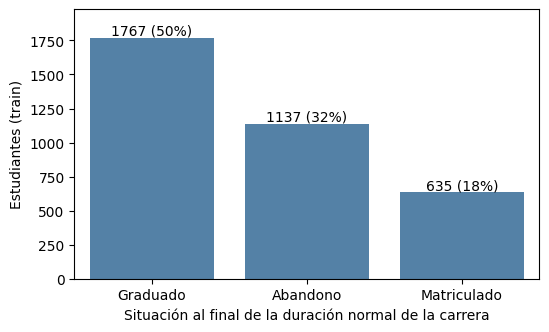

In [10]:
# Figura 2: distribución del target en el train
conteo = train[OBJETIVO].value_counts().rename(index=NOMBRES_CLASES)
figura, eje = plt.subplots(figsize=(6, 3.5))
sns.barplot(x=conteo.index, y=conteo.values, color="steelblue", ax=eje)
for posicion, valor in enumerate(conteo.values):
    eje.text(posicion, valor, f"{valor} ({valor / conteo.sum():.0%})", ha="center", va="bottom")
eje.set_xlabel("Situación al final de la duración normal de la carrera")
eje.set_ylabel("Estudiantes (train)")
eje.set_ylim(0, conteo.max() * 1.12)   # espacio para las etiquetas
utilidades.guardar_figura(figura, "figura_02_target_estudiantes")
plt.show()

**Qué observamos:** en el train, Graduate es la mitad de los casos y Enrolled solo el 18%. Un modelo que prediga siempre Graduate acertaría el 50% de las veces sin aprender nada; por eso la métrica principal es el macro-F1, que pesa igual a las tres clases (diseño, §9).

In [11]:
# Variables numéricas de matrícula: resumen estadístico
continuas_matricula = ["Previous qualification (grade)", "Admission grade", "Age at enrollment"]
train[continuas_matricula].describe().round(1)

,Previous qualification (grade),Admission grade,Age at enrollment
count,3539.0,3539.0,3539.0
mean,132.7,126.9,23.2
std,13.2,14.5,7.6
min,95.0,95.0,17.0
25%,125.0,117.8,19.0
50%,133.1,126.0,20.0
75%,140.0,134.9,25.0
max,190.0,190.0,70.0


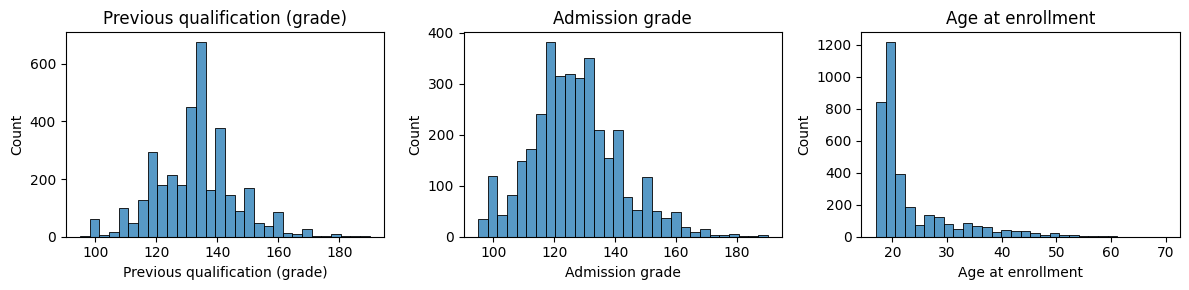

In [12]:
# Histogramas de las mismas variables
figura, ejes = plt.subplots(1, 3, figsize=(12, 3))
for eje, variable in zip(ejes, continuas_matricula):
    sns.histplot(train[variable], bins=30, ax=eje)
    eje.set_title(variable)
plt.tight_layout()
plt.show()

**Qué observamos:** la nota de la calificación previa y la nota de admisión van de 95 a 190, con medianas de 133.1 y 126.0. La edad al matricularse tiene una cola larga hacia la derecha: la mediana es 20 años, pero el máximo es 70. Las escalas son muy distintas entre variables, lo que confirma la necesidad de escalar para KNN y MLP.

In [13]:
# Niveles de cada variable nominal en el train y cuántos representan menos del 1% de las filas
niveles = pd.DataFrame({
    "niveles": [train[v].nunique() for v in NOMINALES],
    "niveles_menos_1pct": [(train[v].value_counts(normalize=True) < 0.01).sum() for v in NOMINALES],
    "filas_en_niveles_raros": [train[v].map(train[v].value_counts(normalize=True) < 0.01).sum()
                               for v in NOMINALES]}, index=NOMINALES)
niveles

,niveles,niveles_menos_1pct,filas_en_niveles_raros
Marital status,6,3,26
Application mode,18,9,117
Course,17,1,10
Previous qualification,17,13,164
Nacionality,19,18,86
Mother's qualification,28,20,105
Father's qualification,32,25,147
Mother's occupation,31,21,117
Father's occupation,41,29,87


**Qué observamos:** salvo Course, que tiene un solo nivel raro, todas las nominales tienen varios niveles con menos del 1% de las filas. Por ejemplo, Nacionality tiene 19 niveles en el train y 18 de ellos reúnen menos del 1% de las filas cada uno (86 filas en total); Father's occupation tiene 41 niveles y 29 son raros. Codificar cada nivel por separado crearía columnas casi vacías; por eso el *one-hot* agrupa los niveles con menos del 1% en una categoría "infrecuente" (diseño, §4.2).

## 5. Análisis multivariante y trampas del dataset (train)

**Qué hacemos:** relacionamos las variables con el target y verificamos las trampas documentadas: cohorte macroeconómica, momento de medición de variables socioeconómicas, fuga temporal de las notas de semestre y asociación de las nominales.

**Por qué:** cada trampa condiciona una decisión de modelado (escenarios, interpretación o codificación); hay que verla en los datos antes de modelar.

In [14]:
# Variables macroeconómicas: ¿cuántas combinaciones distintas hay? (hipótesis: una por cohorte)
MACRO = ["Unemployment rate", "Inflation rate", "GDP"]
print("Valores distintos:", train[MACRO].nunique().to_dict())
print("Combinaciones distintas:", len(train[MACRO].drop_duplicates()))
por_cohorte = pd.crosstab([train[m] for m in MACRO], train[OBJETIVO], normalize="index")
por_cohorte.round(2)

Valores distintos: {'Unemployment rate': 10, 'Inflation rate': 9, 'GDP': 10}
Combinaciones distintas: 10


,,Target,Dropout,Enrolled,Graduate
Unemployment rate,Inflation rate,GDP,,,
7.6,2.6,0.32,0.36,0.21,0.43
8.9,1.4,3.51,0.27,0.21,0.53
9.4,-0.8,-3.12,0.32,0.20,0.48
10.8,1.4,1.74,0.36,0.16,0.48
11.1,0.6,2.02,0.29,0.16,0.55
12.4,0.5,1.79,0.23,0.21,0.56
12.7,3.7,-1.70,0.34,0.15,0.51
13.9,-0.3,0.79,0.31,0.17,0.52
15.5,2.8,-4.06,0.35,0.18,0.47


**Qué observamos:** las tres variables macroeconómicas forman exactamente 10 combinaciones distintas, una por cohorte de ingreso. La proporción de abandono varía entre cohortes de 0.23 a 0.38. Estas variables funcionan como un identificador del año de ingreso, no como una medida individual; si aparecen como importantes en el modelo, se interpretarán como efecto de cohorte (diseño, §10).

In [15]:
# Situación final según tres variables socioeconómicas binarias (proporción por fila)
for variable in ["Debtor", "Tuition fees up to date", "Scholarship holder"]:
    print(variable)
    print(pd.crosstab(train[variable], train[OBJETIVO], normalize="index").round(2), "\n")

Debtor
Target  Dropout  Enrolled  Graduate
Debtor                             
0          0.28      0.18      0.54
1          0.64      0.18      0.18 

Tuition fees up to date
Target                   Dropout  Enrolled  Graduate
Tuition fees up to date                             
0                           0.87      0.08      0.05
1                           0.25      0.19      0.56 

Scholarship holder
Target              Dropout  Enrolled  Graduate
Scholarship holder                             
0                      0.39      0.20      0.41
1                      0.13      0.12      0.76 



**Qué observamos:** las tres variables están fuertemente asociadas con la situación final. Entre quienes no tienen la matrícula al día, el 87% abandona, frente al 25% de quienes sí la tienen; entre los deudores, el 64% abandona. El dataset no indica cuándo se registraron estas dos variables: si se midieron después de la matrícula, en el escenario E1 serían información del futuro. Se declara como limitación y se evalúa en la sensibilidad sin Debtor ni Tuition fees (extra 4 del diseño).

In [16]:
# Notas del 1.er y 2.º semestre por situación final (estas variables solo existen en E2)
SEMESTRE = ["Curricular units 1st sem (approved)", "Curricular units 2nd sem (approved)",
            "Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)"]
train.groupby(OBJETIVO)[SEMESTRE].mean().round(2)

,Curricular units 1st sem (approved),Curricular units 2nd sem (approved),Curricular units 1st sem (grade),Curricular units 2nd sem (grade)
Target,,,,
Dropout,2.57,1.94,7.21,5.84
Enrolled,4.36,4.10,11.14,11.15
Graduate,6.20,6.16,12.63,12.67


In [17]:
# Estudiantes sin unidades inscritas en el 1.er semestre: ¿errores o casos legítimos?
sin_unidades = train[train["Curricular units 1st sem (enrolled)"] == 0]
print("Casos en train:", len(sin_unidades))
print(sin_unidades[OBJETIVO].value_counts().to_dict())
print("Nota del 1.er semestre en esos casos:", sin_unidades["Curricular units 1st sem (grade)"].unique())

Casos en train: 148
{'Graduate': 64, 'Dropout': 63, 'Enrolled': 21}
Nota del 1.er semestre en esos casos: [0.]


**Qué observamos:** las unidades aprobadas y las notas del 1.er y 2.º semestre separan con claridad a las tres clases (por ejemplo, 1.94 unidades aprobadas en el 2.º semestre para Dropout frente a 6.16 para Graduate). Esto confirma la fuga temporal: con estas variables la tarea se vuelve mucho más fácil, pero no existen al momento de matricularse. Los 148 estudiantes del train sin unidades inscritas en el 1.er semestre tienen nota 0 y se reparten entre las tres clases (64 Graduate, 63 Dropout, 21 Enrolled), así que los ceros son casos legítimos y no errores.

In [18]:
# Asociación de cada variable categórica con el target: chi² (curso) y V de Cramér (tamaño del efecto)
from scipy.stats import chi2_contingency

filas = []
for variable in NOMINALES + BINARIAS:
    tabla = pd.crosstab(train[variable], train[OBJETIVO])
    chi2, p_valor, _, _ = chi2_contingency(tabla)
    v_cramer = (chi2 / (tabla.values.sum() * (min(tabla.shape) - 1))) ** 0.5
    filas.append({"variable": variable, "chi2": round(chi2, 1), "p_valor": p_valor, "v_cramer": round(v_cramer, 3)})
asociacion = pd.DataFrame(filas).sort_values("v_cramer", ascending=False)
asociacion

,variable,chi2,p_valor,v_cramer
13,Tuition fees up to date,661.0,2.920120e-144,0.432
15,Scholarship holder,321.4,1.618302e-70,0.301
2,Course,458.4,5.833403e-77,0.255
12,Debtor,226.1,7.918058e-50,0.253
1,Application mode,429.3,6.254550e-70,0.246
14,Gender,184.2,1.021572e-40,0.228
7,Mother's occupation,256.7,3.745118e-26,0.190
8,Father's occupation,250.5,1.881192e-19,0.188
6,Father's qualification,201.2,1.315696e-16,0.169
3,Previous qualification,186.7,9.117382e-24,0.162


**Qué observamos:** con 3539 filas, casi todas las pruebas chi² dan valores *p* muy pequeños, por eso la V de Cramér es más informativa sobre la fuerza de la asociación. Las asociaciones más fuertes son Tuition fees up to date (0.43), Scholarship holder (0.30), Course (0.26), Debtor (0.25) y Application mode (0.25). Nacionality, International y Educational special needs casi no se asocian con el target (V < 0.08). En las nominales con muchos niveles raros, la aproximación chi² es poco fiable porque hay celdas con frecuencias esperadas bajas; se usa solo como descripción.

In [19]:
# Correlación entre numéricas: pares con |r| > 0.8 (información redundante)
NUMERICAS = [v for v in utilidades.COLUMNAS_ESTUDIANTES if v not in NOMINALES + BINARIAS]
correlacion = train[NUMERICAS].corr()
triangulo = np.triu(np.ones(correlacion.shape, dtype=bool), k=1)
pares = correlacion.where(triangulo).stack()
pares[pares.abs() > 0.8].sort_values(ascending=False).round(2)

Curricular units 1st sem (credited)  Curricular units 2nd sem (credited)    0.95
Curricular units 1st sem (enrolled)  Curricular units 2nd sem (enrolled)    0.94
Curricular units 1st sem (approved)  Curricular units 2nd sem (approved)    0.91
Curricular units 1st sem (grade)     Curricular units 2nd sem (grade)       0.84
dtype: float64

**Qué observamos:** solo hay correlaciones altas entre las variables del 1.er y del 2.º semestre (r de 0.84 a 0.95), que miden lo mismo en dos momentos. Esa redundancia afecta solo al escenario E2 y es un argumento para probar la selección de variables (diseño, §6).

## 6. Valores atípicos (diagnóstico)

**Qué hacemos:** aplicamos la regla IQR por variable e Isolation Forest sobre todas las numéricas.

**Por qué:** son técnicas del curso; aquí sirven solo como diagnóstico. No se eliminan filas porque los extremos de este dataset son plausibles (diseño, §4.2).

In [20]:
# Regla IQR: filas del train fuera de [Q1 − 1.5·IQR, Q3 + 1.5·IQR] en cada variable continua
CONTINUAS = continuas_matricula + ["Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)"]
q1, q3 = train[CONTINUAS].quantile(0.25), train[CONTINUAS].quantile(0.75)
rango = q3 - q1
fuera = (train[CONTINUAS] < q1 - 1.5 * rango) | (train[CONTINUAS] > q3 + 1.5 * rango)
pd.DataFrame({"filas_fuera": fuera.sum(), "limite_inferior": (q1 - 1.5 * rango).round(1),
              "limite_superior": (q3 + 1.5 * rango).round(1)})

,filas_fuera,limite_inferior,limite_superior
Previous qualification (grade),135,102.5,162.5
Admission grade,68,92.1,160.6
Age at enrollment,358,10.0,34.0
Curricular units 1st sem (grade),592,7.4,17.0
Curricular units 2nd sem (grade),711,6.9,17.2


In [21]:
# Isolation Forest sobre todas las numéricas (marca el 2% más aislado; solo diagnóstico)
from sklearn.ensemble import IsolationForest

bosque = IsolationForest(contamination=0.02, random_state=utilidades.SEMILLA)
es_atipica = bosque.fit_predict(train[NUMERICAS]) == -1
print("Filas marcadas:", es_atipica.sum())
print("Situación final de las marcadas:", train.loc[es_atipica, OBJETIVO].value_counts().to_dict())
train.loc[es_atipica, CONTINUAS].describe().round(1)

Filas marcadas: 71
Situación final de las marcadas: {'Graduate': 47, 'Dropout': 19, 'Enrolled': 5}


,Previous qualification (grade),Admission grade,Age at enrollment,Curricular units 1st sem (grade),Curricular units 2nd sem (grade)
count,71.0,71.0,71.0,71.0,71.0
mean,131.7,128.3,30.5,12.0,12.1
std,14.6,14.0,9.4,2.8,2.8
min,100.0,100.0,18.0,0.0,0.0
25%,121.0,120.0,23.0,11.6,11.6
50%,130.0,127.2,28.0,12.3,12.2
75%,140.0,133.9,35.0,13.2,13.2
max,180.0,180.0,57.0,16.5,16.9


**Qué observamos:** la regla IQR marca muchas filas en las notas de semestre (592 y 711) porque los ceros de quienes no tuvieron evaluaciones quedan por debajo del límite inferior; ya vimos que esos ceros son legítimos. En la edad marca 358 estudiantes mayores de 34 años, un grupo real (estudiantes adultos) y no un error. Isolation Forest marca 71 filas (2%), con edad media de 30.5 años frente a 23.2 en todo el train. Ninguna de las dos técnicas detecta errores de registro, así que no se elimina ninguna fila (diseño, §4.2).

## 7. Decisiones de preprocesamiento que se derivan

| Hallazgo (sección) | Decisión | Diseño |
|---|---|---|
| Sin faltantes ni duplicados (2) | No se imputa ni se eliminan filas | §4.1 |
| Clases desbalanceadas: Enrolled 18% (4) | Métrica principal macro-F1; SMOTENC dentro de cada *fold* frente a no balancear | §5 y §9 |
| Nominales con muchos niveles raros (4) | *One-hot* con agrupación de niveles con menos del 1% | §4.2 |
| Escalas muy distintas (4) | `StandardScaler` en las numéricas, necesario para KNN y MLP | §4.2 |
| Notas de semestre separan las clases (5) | Dos escenarios: E1 al matricularse (principal) y E2 fin del 2.º semestre | §1 |
| Macroeconómicas = 10 cohortes (5) | Se mantienen; su importancia se interpreta como efecto de cohorte | §10 |
| Debtor y Tuition fees muy asociadas y sin fecha de registro (5) | Se mantienen en E1; limitación declarada y sensibilidad sin ellas | §1 y §14 |
| Ceros de semestre y edades altas legítimos (5 y 6) | No se eliminan atípicos; IQR e Isolation Forest solo como diagnóstico | §4.2 |
| Semestres 1 y 2 muy correlacionados (5) | Se evalúa la selección L1 | §6 |

## Guardar resultados en GitHub (solo corrida oficial en Colab)

**Qué hacemos:** subimos a `main` los archivos de `resultados/` que genera este notebook.

**Por qué:** las cifras del reporte deben salir de la misma corrida que deja las salidas visibles en el notebook (§12, regla 4). En VS Code esta celda no hace nada; Marcelo hace el *commit* desde VS Code. Después de esta celda, guardar el notebook con *File → Save a copy in GitHub*.

In [22]:
# Celda final. Cambiar a True solo en la corrida oficial, después de "Reiniciar y ejecutar todo".
import glob

GUARDAR_EN_GITHUB = False
PATRONES_DE_ESTE_NOTEBOOK = ["resultados/tablas/tabla_01_*estudiantes.csv", "resultados/figuras/figura_0[23]_*estudiantes.png"]
if EN_COLAB and GUARDAR_EN_GITHUB:
    archivos = " ".join(f for patron in PATRONES_DE_ESTE_NOTEBOOK for f in sorted(glob.glob(patron)))
    nombre, correo = userdata.get("GITHUB_NOMBRE"), userdata.get("GITHUB_CORREO")
    !git config user.name "{nombre}"
    !git config user.email "{correo}"
    !git add {archivos}
    !git commit -q -m "01-estudiantes: actualiza resultados de la corrida oficial"
    !git pull -q --rebase
    !git push -q
    print("Archivos subidos:", archivos)